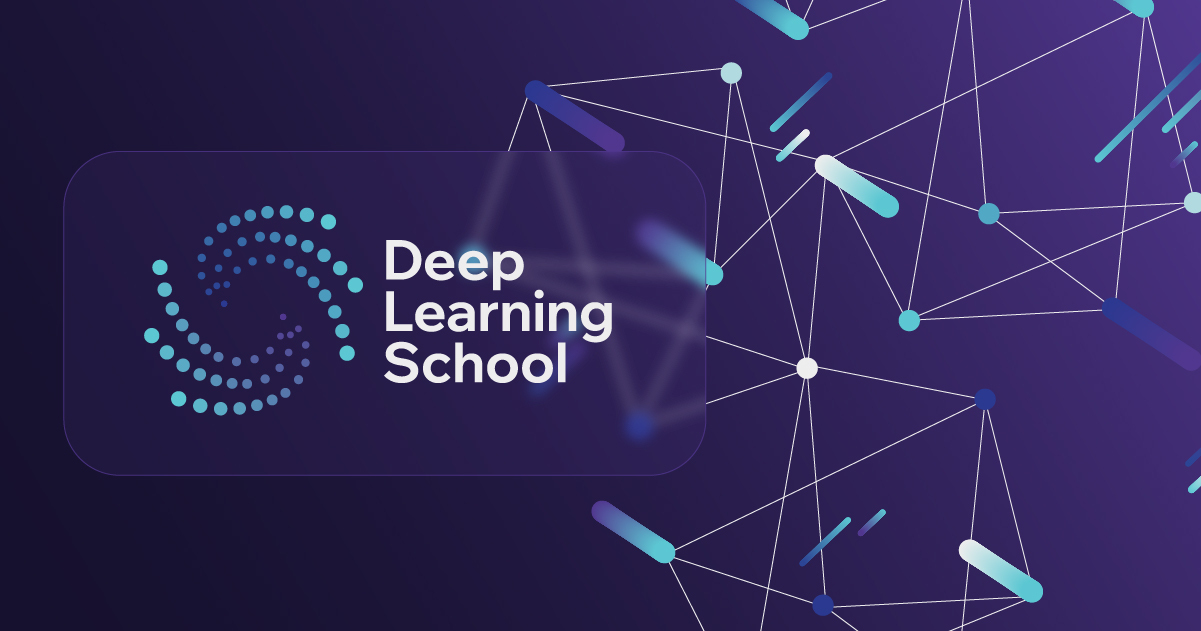

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание по теме "Механизм внимания.</b></h1>


Это домашнее задание проходит в формате peer-review. Это означает, что его будут проверять ваши однокурсники. Поэтому пишите разборчивый код, добавляйте комментарии и пишите выводы после проделанной работы.

В этом задании вы будете решать задачу классификации математических задач по темам (многоклассовая классификация) с помощью Transformer.

В качестве датасета возьмем датасет математических задач по разным темам. Нам необходим следующий файл:

[Файл с классами](https://docs.google.com/spreadsheets/d/13YIbphbWc62sfa-bCh8MLQWKizaXbQK9/edit?usp=drive_link&ouid=104379615679964018037&rtpof=true&sd=true)

**Hint:** не перезаписывайте модели, которые вы получите на каждом из этапов этого дз. Они ещё понадобятся.

### Подготовка данных

In [1]:
import pandas as pd
from datasets import Dataset


file_id = "13YIbphbWc62sfa-bCh8MLQWKizaXbQK9"
file_url = f"https://docs.google.com/spreadsheets/d/{file_id}/export?format=xlsx"

df = pd.read_excel(file_url)
df = df.dropna()

dataset = Dataset.from_pandas(df)
dataset = dataset.rename_column("topic", "labels")
dataset = dataset.class_encode_column("labels")
dataset = dataset.train_test_split(test_size=0.2, seed=42)

print("Number of classes:", df["topic"].nunique())

Casting to class labels:   0%|          | 0/5268 [00:00<?, ? examples/s]

Number of classes: 7


### Задание 1 (2 балла)

Напишите кастомный класс для модели трансформера для задачи классификации, использующей в качествке backbone какую-то из моделей huggingface.

Т.е. конструктор класса должен принимать на вход название модели и подгружать её из huggingface, а затем использовать в качестве backbone (достаточно возможности использовать в качестве backbone те модели, которые упомянуты в последующих пунктах)

In [2]:
import torch.nn as nn
from transformers import AutoModel


class TransformerClassificationModel(nn.Module):
    def __init__(self, model_name, cnt_class=7):
        super().__init__()

        self.backbone = AutoModel.from_pretrained(model_name)
        self.hid_dim = self.backbone.config.hidden_size
        self.classifier_head = nn.Linear(self.hid_dim, cnt_class)
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, input_ids, attention_mask=None, labels=None):
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        x = outputs.last_hidden_state[:, 0, :]
        logits = self.classifier_head(x)

        result = {"logits": logits}

        if labels is not None:
            result["loss"] = self.loss_fn(logits, labels.long())

        return result

### Задание 2 (1 балл)

Напишите функцию заморозки backbone у модели (если необходимо, возвращайте из функции модель)

In [3]:
def freeze_backbone_function(model: TransformerClassificationModel):
    for param in model.backbone.parameters():
        param.requires_grad = False

    return model

### Задание 3 (2 балла)

Напишите функцию, которая будет использована для тренировки (дообучения) трансформера (TransformerClassificationModel). Функция должна поддерживать обучение с замороженным и размороженным backbone.

In [4]:
import copy
import torch
from transformers import AutoTokenizer, Trainer, TrainingArguments
import numpy as np
from sklearn.metrics import f1_score


def prepare_dataloader(dataset, tokenizer, max_length=256):
    def tokenize(batch):
        return tokenizer(
            batch["problem_text"],
            truncation=True,
            padding="max_length",
            max_length=max_length
        )

    return dataset.map(
        tokenize,
        batched=True,
        remove_columns=["problem_text"]
    )


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "f1": f1_score(labels, predictions, average="macro")
    }


def train_transformer(
    transformer_model,
    dataset,
    freeze_backbone=True,
    epochs=3,
    batch_size=16,
    lr=2e-5,
    max_length=256,
):
    model = copy.deepcopy(transformer_model)

    for param in model.backbone.parameters():
        param.requires_grad = not freeze_backbone

    tokenizer = AutoTokenizer.from_pretrained(
        model.backbone.config._name_or_path
    )
    dataset = prepare_dataloader(dataset, tokenizer, max_length)

    args = TrainingArguments(
        output_dir="./results",
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        learning_rate=lr,
        eval_strategy="epoch",
        save_strategy="no",
        report_to="none",
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=dataset["train"],
        eval_dataset=dataset["test"],
        compute_metrics=compute_metrics,
    )

    trainer.train()
    metrics = trainer.evaluate()

    return model, metrics

### Задание 4 (1 балл)

Проверьте вашу функцию из предыдущего пункта, дообучив двумя способами
*cointegrated/rubert-tiny2* из huggingface.

In [7]:
rubert_tiny_transformer_model = TransformerClassificationModel(
    "cointegrated/rubert-tiny2"
)

rubert_frozen, rubert_frozen_metrics = train_transformer(
    rubert_tiny_transformer_model,
    dataset=dataset,
    freeze_backbone=True
)

rubert_full, rubert_full_metrics = train_transformer(
    rubert_tiny_transformer_model,
    dataset=dataset,
    freeze_backbone=False
)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Map:   0%|          | 0/4214 [00:00<?, ? examples/s]

Map:   0%|          | 0/1054 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,F1
1,No log,1.791761,0.140333
2,1.824471,1.714671,0.109262
3,1.824471,1.693121,0.102658


Training Loss,Validation Loss,Epoch,F1
1.824471,1.693121,3,0.102658


Map:   0%|          | 0/4214 [00:00<?, ? examples/s]

Map:   0%|          | 0/1054 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,F1
1,No log,1.203383,0.337809
2,1.279657,1.109063,0.389840
3,1.279657,1.086680,0.396835


Training Loss,Validation Loss,Epoch,F1
1.279657,1.086680,3,0.396835


### Задание 5 (1 балл)

Обучите *tbs17/MathBert* (с замороженным backbone и без заморозки), проанализируйте результаты. Сравните скоры с первым заданием. Получилось лучше или нет? Почему?

In [8]:
mathbert_model = TransformerClassificationModel(
    "tbs17/MathBert"
)

mathbert_frozen, mathbert_frozen_metrics = train_transformer(
    mathbert_model,
    dataset,
    freeze_backbone=True
)

mathbert_full, mathbert_full_metrics = train_transformer(
    mathbert_model,
    dataset,
    freeze_backbone=False
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Map:   0%|          | 0/4214 [00:00<?, ? examples/s]

Map:   0%|          | 0/1054 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,F1
1,No log,1.597292,0.126511
2,1.697406,1.563268,0.114614
3,1.697406,1.555490,0.114619


Training Loss,Validation Loss,Epoch,F1
1.697406,1.555490,3,0.114619


Map:   0%|          | 0/4214 [00:00<?, ? examples/s]

Map:   0%|          | 0/1054 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,F1
1,No log,0.977636,0.438401
2,0.999749,1.006862,0.447699
3,0.999749,1.039304,0.447049


Training Loss,Validation Loss,Epoch,F1
0.999749,1.039304,3,0.447049


,Model,F1
0,RuBERT Frozen,0.102658
1,RuBERT Full,0.396835
2,MathBERT Frozen,0.114619
3,MathBERT Full,0.447049


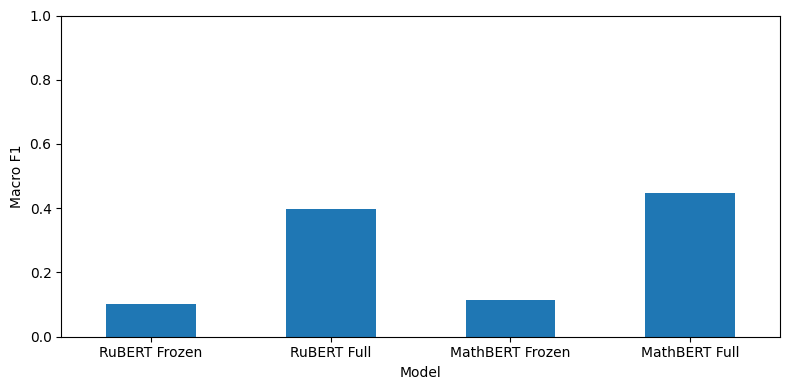

In [9]:
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Model": [
        "RuBERT Frozen",
        "RuBERT Full",
        "MathBERT Frozen",
        "MathBERT Full"
    ],
    "F1": [
        rubert_frozen_metrics["eval_f1"],
        rubert_full_metrics["eval_f1"],
        mathbert_frozen_metrics["eval_f1"],
        mathbert_full_metrics["eval_f1"]
    ]
})

display(results)

results.plot.bar(
    x="Model",
    y="F1",
    figsize=(8, 4),
    rot=0,
    legend=False
)

plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

####Выводы:

- Полное дообучение значительно улучшило результаты обеих моделей. При замороженном backbone качество классификации оказалось очень низким (F1 ≈ 0.10-0.11).
- **MathBERT показал лучший результат** (F1 = 0.447 против 0.397 у RuBERT).
- Преимущество MathBERT может объясняться его специализацией на математических текстах, благодаря чему модель лучше распознаёт особенности предметной области.

Таким образом, полное дообучение оказалось значительно эффективнее обучения только классификационной головы, а MathBERT лучше справился с данной задачей.

### Задание 6 (1 балл)

Напишите функцию для отрисовки карт внимания первого слоя для моделей из задания

In [18]:
import seaborn as sns
from typing import List

def draw_first_layer_attention_maps(
    attention_head_ids: List,
    text: str,
    model: TransformerClassificationModel
):
    print(f"Text: {text}\n")

    model.eval()
    model.backbone.set_attn_implementation("eager")

    device = next(model.parameters()).device

    tokenizer = AutoTokenizer.from_pretrained(
        model.backbone.config._name_or_path
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        outputs = model.backbone(
            **inputs,
            output_attentions=True,
            return_dict=True
        )

    attention = outputs.attentions[0][0].cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    fig, axes = plt.subplots(
        1, len(attention_head_ids),
        figsize=(6 * len(attention_head_ids), 5),
        squeeze=False
    )

    for ax, head_id in zip(axes[0], attention_head_ids):
        sns.heatmap(
            attention[head_id],
            xticklabels=tokens,
            yticklabels=tokens,
            cmap="viridis",
            ax=ax
        )
        ax.set_title(f"Head {head_id}")
        ax.set_xlabel("Key tokens")
        ax.set_ylabel("Query tokens")

    plt.tight_layout()
    plt.show()

Text: To prove that the sum of the numbers of the exact square cannot be equal to 5.



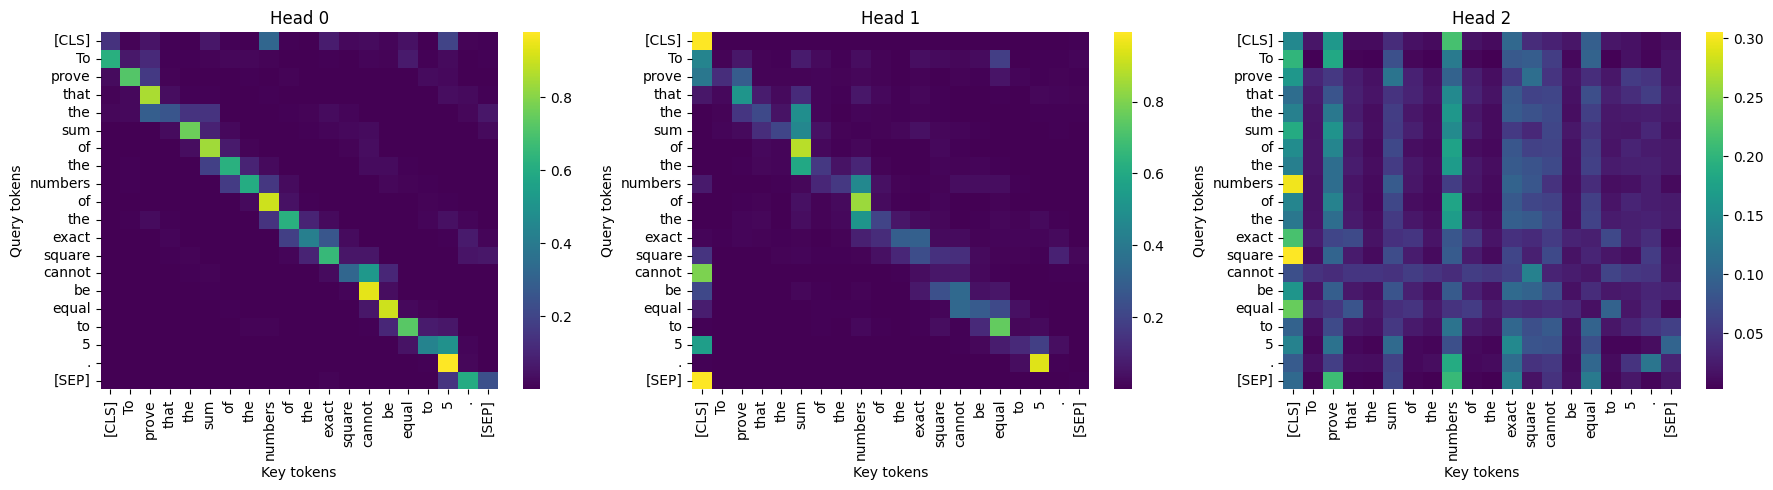

In [19]:
text = df["problem_text"].iloc[0]

draw_first_layer_attention_maps(
    attention_head_ids=[0, 1, 2],
    text=text,
    model=rubert_tiny_transformer_model
)

### Задание 7 (1 балл)

Проведите инференс для всех моделей ДО ДООБУЧЕНИЯ на 2-3 текстах из датасета. Посмотрите на головы Attention первого слоя в каждой модели на выбранных текстах (отрисуйте их отдельно).

Попробуйте их проинтерпретировать. Какие связи улавливают карты внимания? (если в модели много голов Attention, то проинтерпретируйте наиболее интересные)



Backbone model: cointegrated/rubert-tiny2

Text: To prove that the sum of the numbers of the exact square cannot be equal to 5.



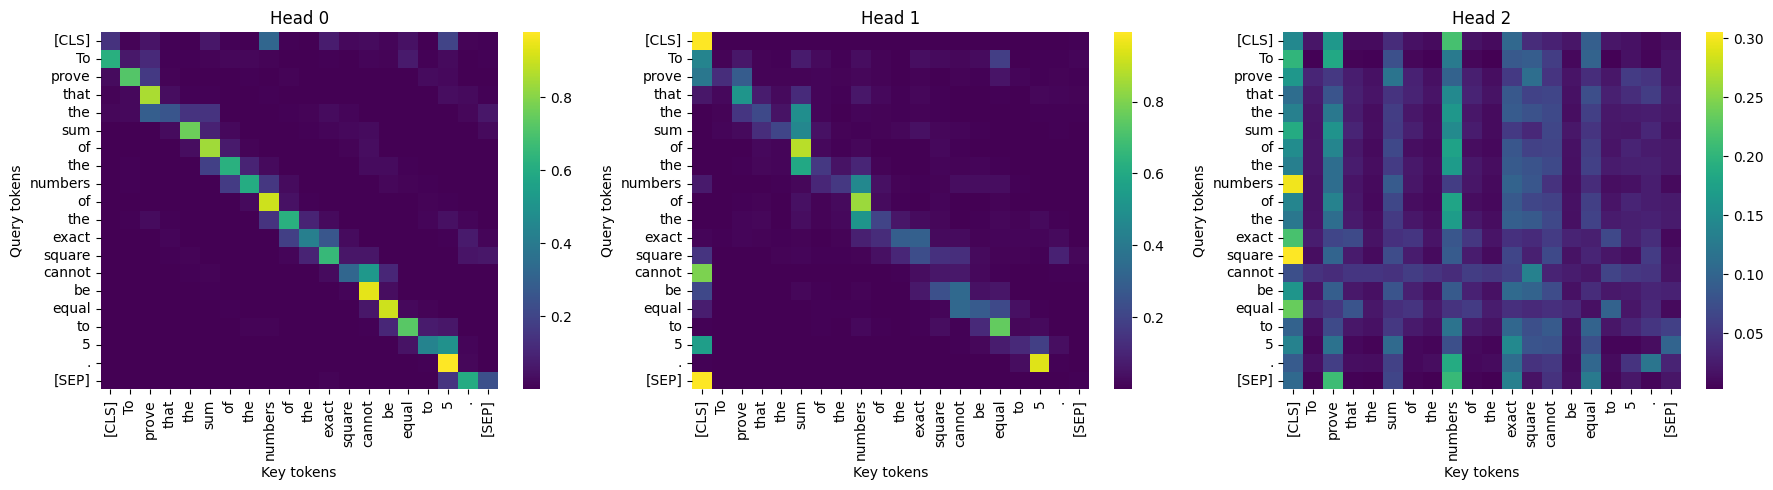



Backbone model: tbs17/MathBert

Text: To prove that the sum of the numbers of the exact square cannot be equal to 5.



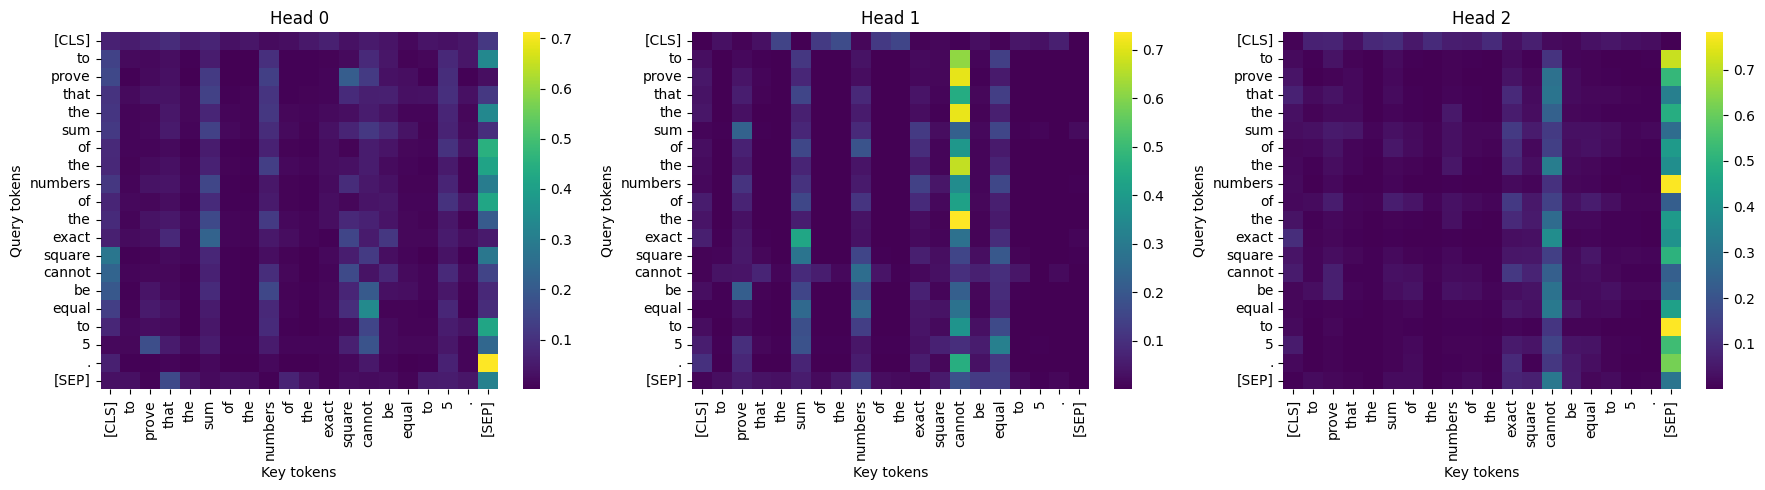



Backbone model: cointegrated/rubert-tiny2

Text: ( b) Will the statement of the previous challenge remain true if Petia and Wasa originally planned four natural numbers?



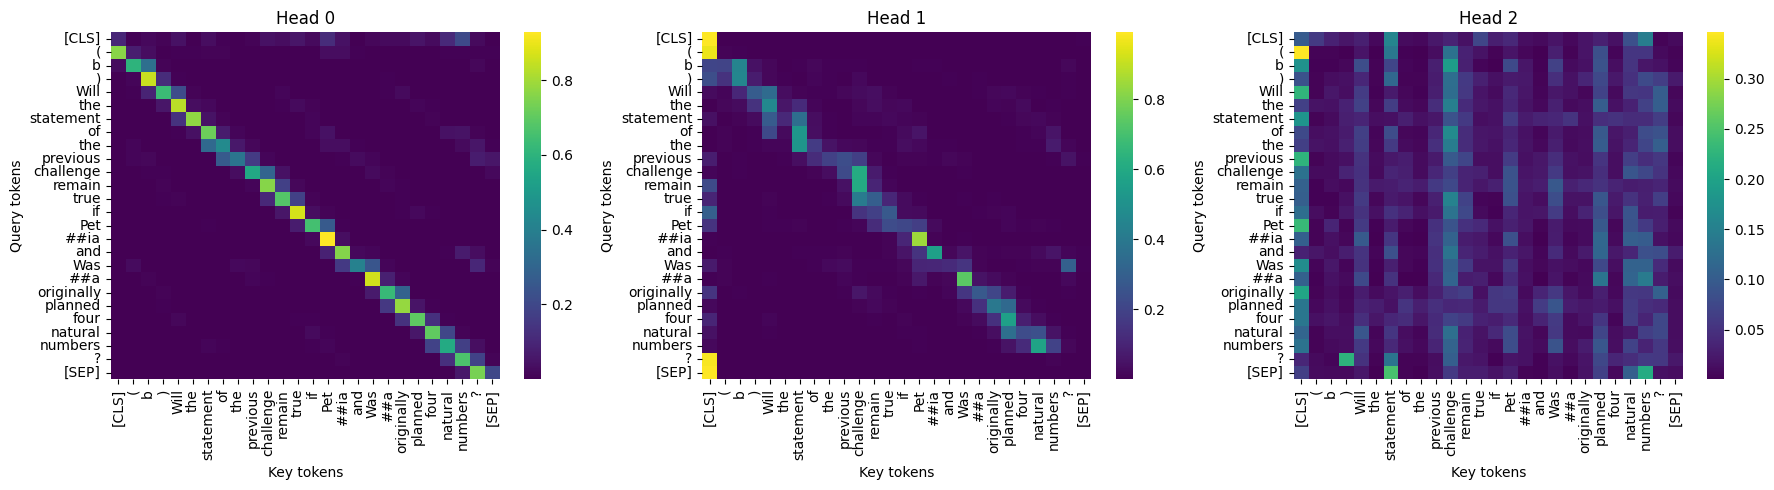



Backbone model: tbs17/MathBert

Text: ( b) Will the statement of the previous challenge remain true if Petia and Wasa originally planned four natural numbers?



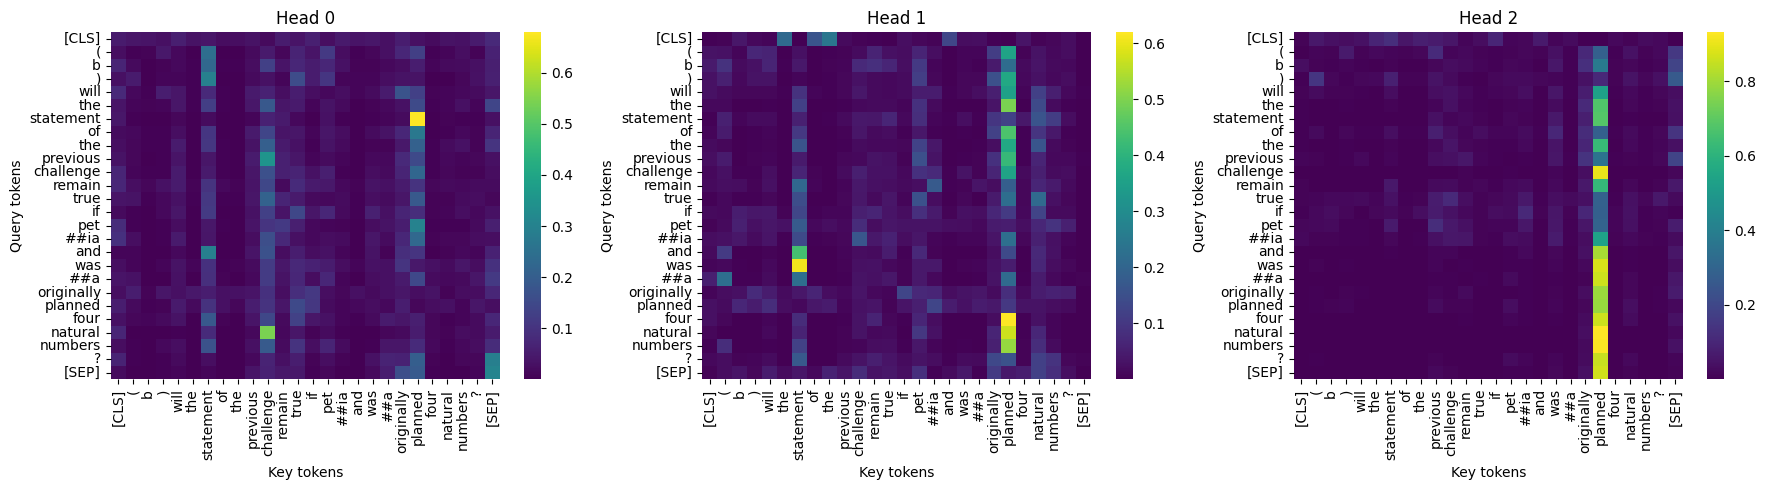



Backbone model: cointegrated/rubert-tiny2

Text: The quadratic three-member graph with the coefficients has two points with the coordinates. Show that if the distance between them is the whole number, then the fraction is parallel to the abscisse axis.



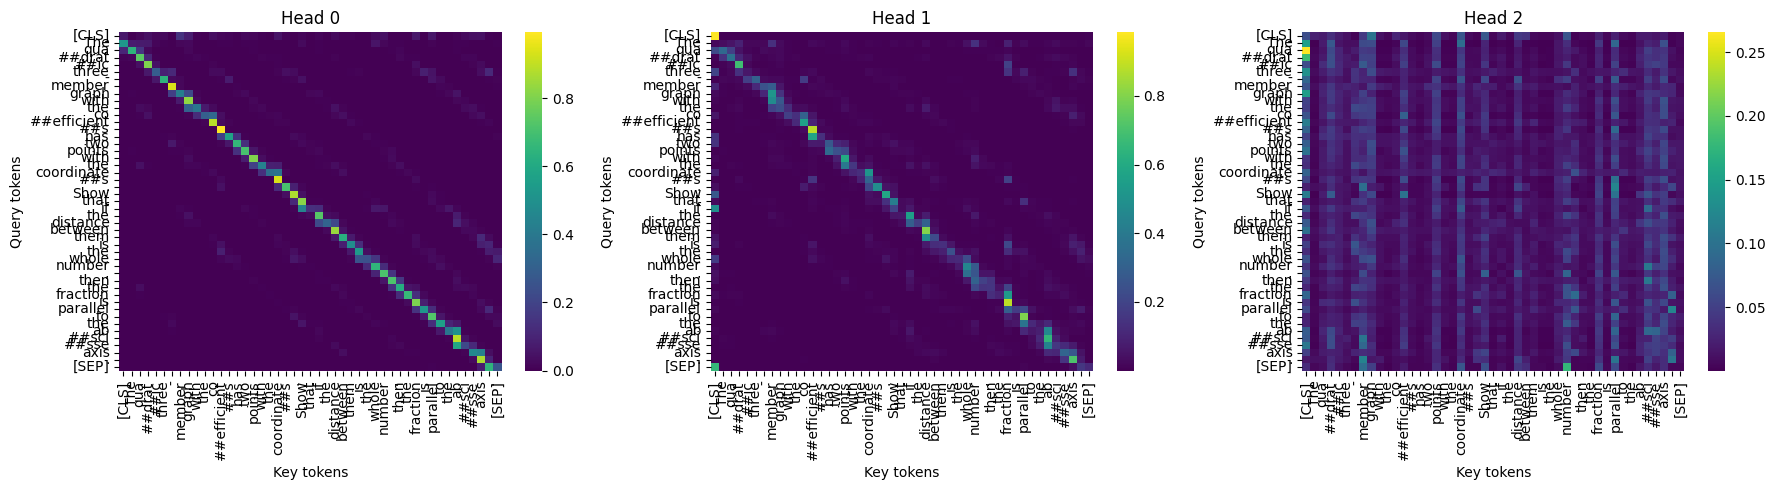



Backbone model: tbs17/MathBert

Text: The quadratic three-member graph with the coefficients has two points with the coordinates. Show that if the distance between them is the whole number, then the fraction is parallel to the abscisse axis.



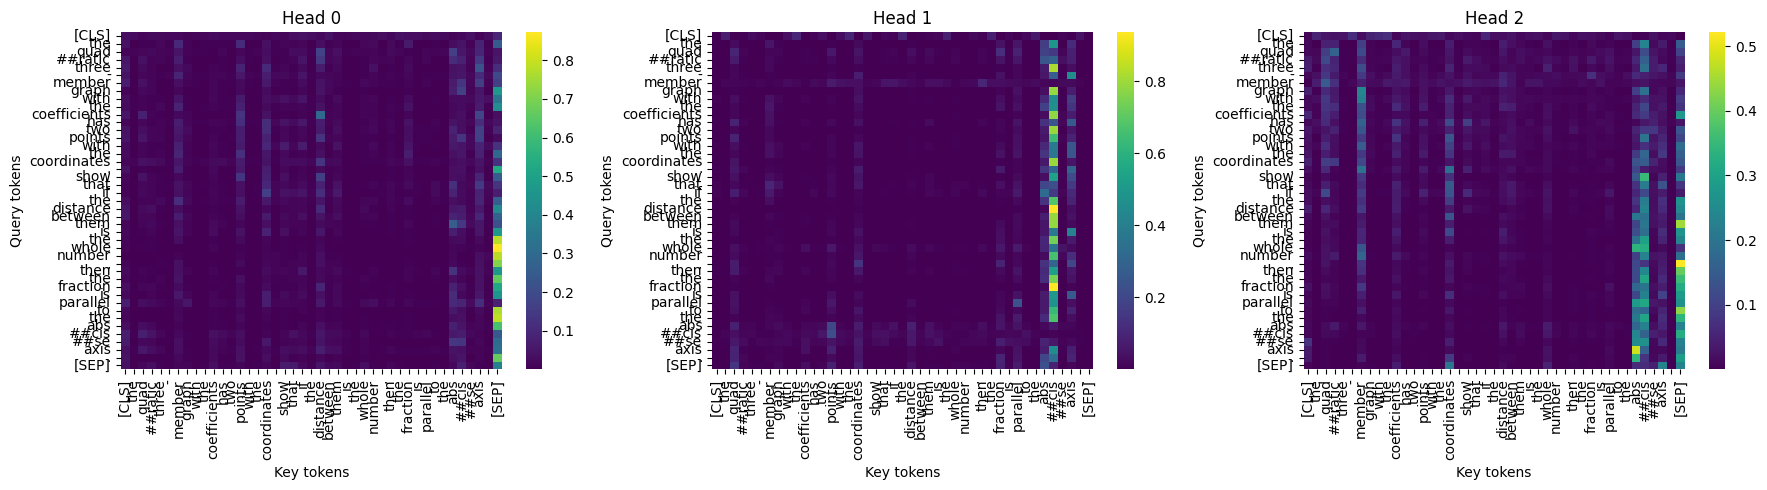

In [22]:
texts = df["problem_text"].iloc[:3].tolist()

for text in texts:
    for model in [rubert_tiny_transformer_model, mathbert_model]:
        print("\n")
        print(f"Backbone model: {model.backbone.config._name_or_path}\n")
        draw_first_layer_attention_maps([0, 1, 2], text, model)

#### Интерпретация

**RuBERT-tiny2:**
- **Head 0** демонстрирует выраженное диагональное внимание: токены преимущественно обращают внимание на самих себя.
- **Head 1** также ориентирована на локальные связи, включая соседние токены и специальный токен `[CLS]`.
- **Head 2** распределяет внимание более широко, выделяя отдельные слова и позиции в предложении.

**MathBERT:**
- Карты внимания заметно отличаются от RuBERT. Вместо диагональных паттернов преобладают вертикальные полосы.
- Отдельные головы концентрируют внимание на конкретных токенах, например `square`, `numbers`, а также на специальных токенах.
- Такое распределение может отражать более избирательное внимание к отдельным элементам текста, но не доказывает понимания математических связей.

### Задание 8 (1 балл)

Сделайте то же самое для дообученных моделей. Изменились ли карты внимания и связи, которые они улавливают? Почему?



Backbone model: cointegrated/rubert-tiny2

Text: To prove that the sum of the numbers of the exact square cannot be equal to 5.



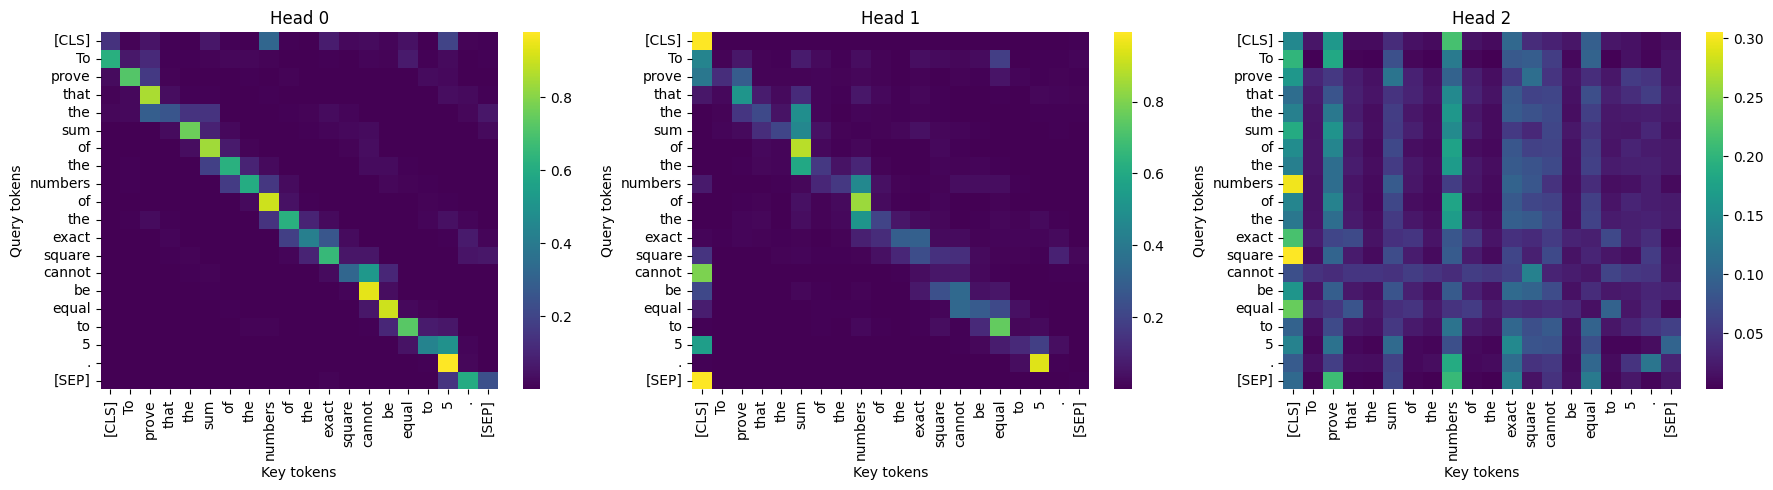



Backbone model: cointegrated/rubert-tiny2

Text: To prove that the sum of the numbers of the exact square cannot be equal to 5.



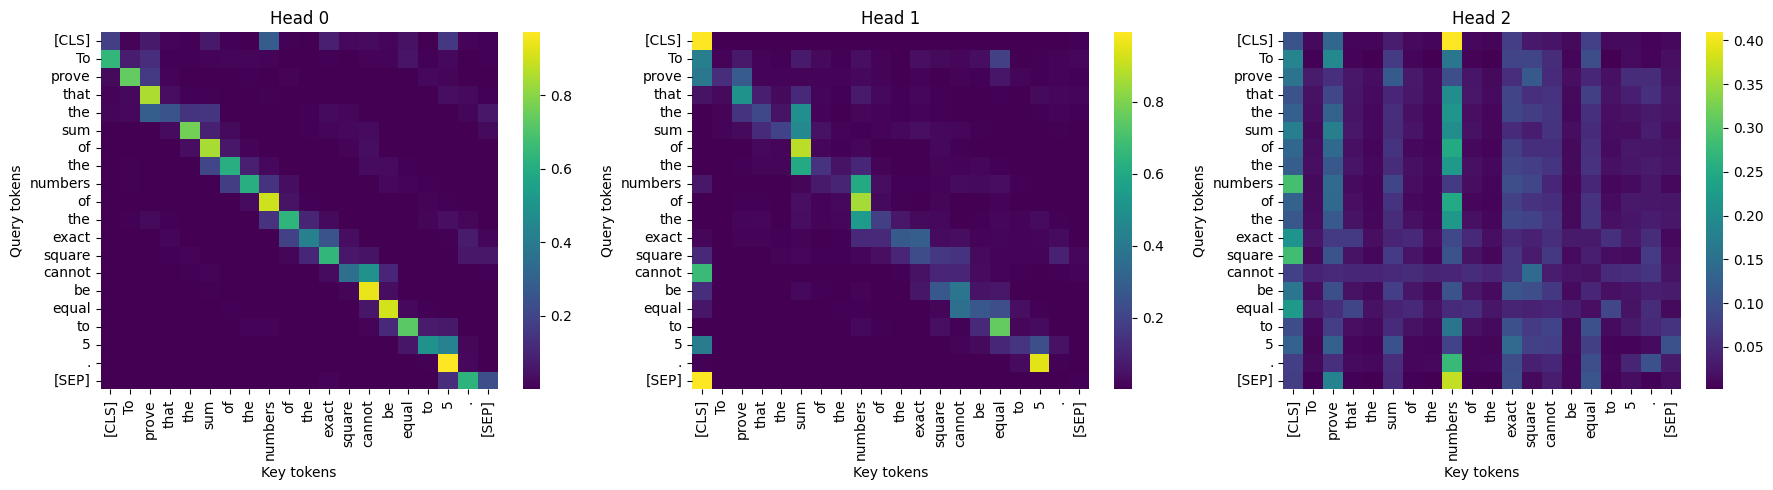



Backbone model: tbs17/MathBert

Text: To prove that the sum of the numbers of the exact square cannot be equal to 5.



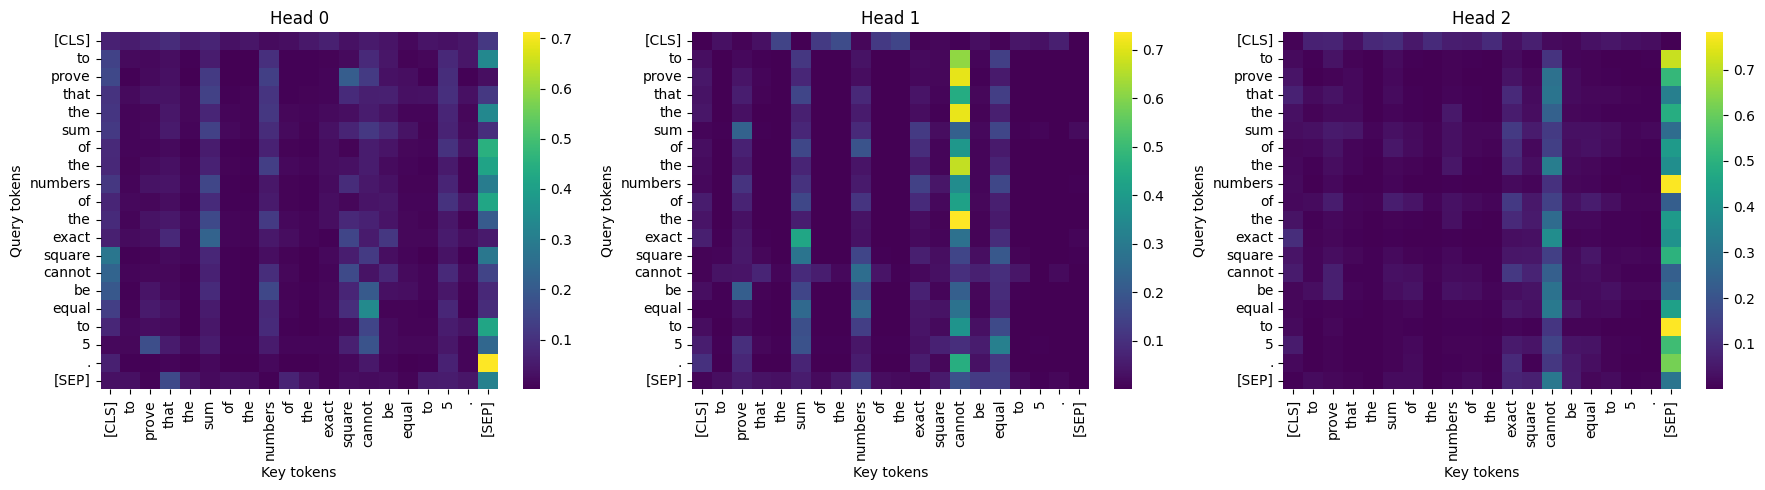



Backbone model: tbs17/MathBert

Text: To prove that the sum of the numbers of the exact square cannot be equal to 5.



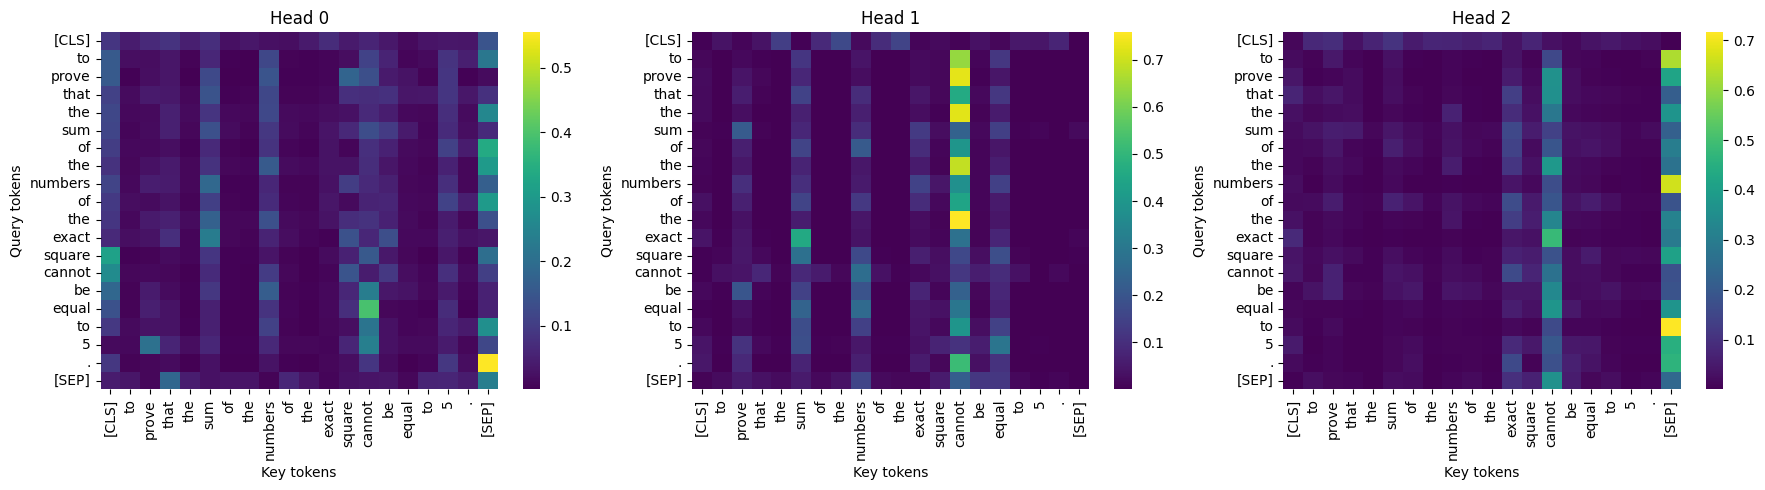



Backbone model: cointegrated/rubert-tiny2

Text: ( b) Will the statement of the previous challenge remain true if Petia and Wasa originally planned four natural numbers?



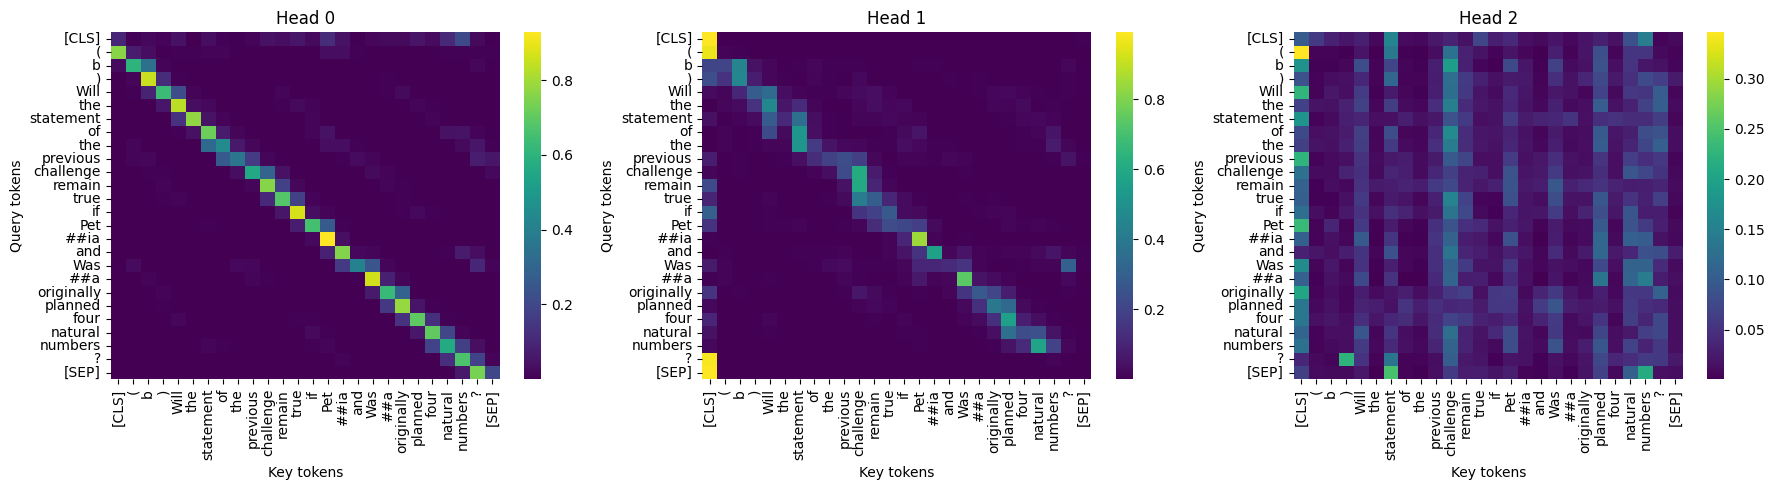



Backbone model: cointegrated/rubert-tiny2

Text: ( b) Will the statement of the previous challenge remain true if Petia and Wasa originally planned four natural numbers?



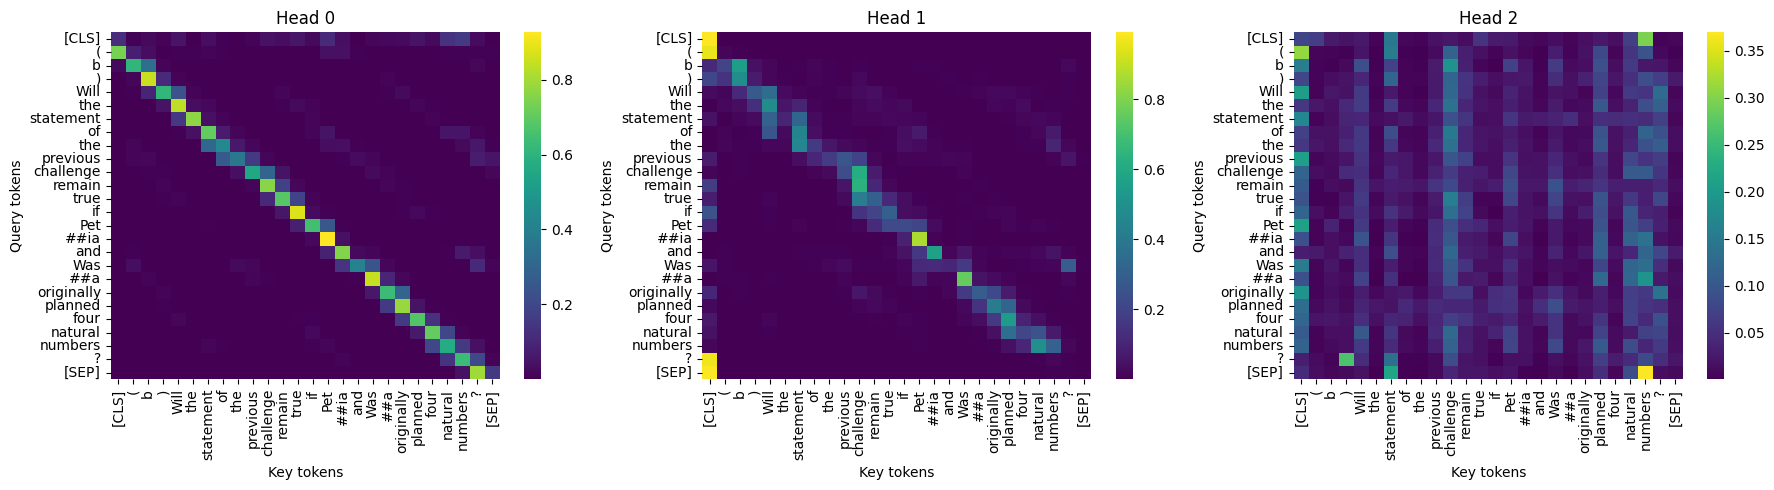



Backbone model: tbs17/MathBert

Text: ( b) Will the statement of the previous challenge remain true if Petia and Wasa originally planned four natural numbers?



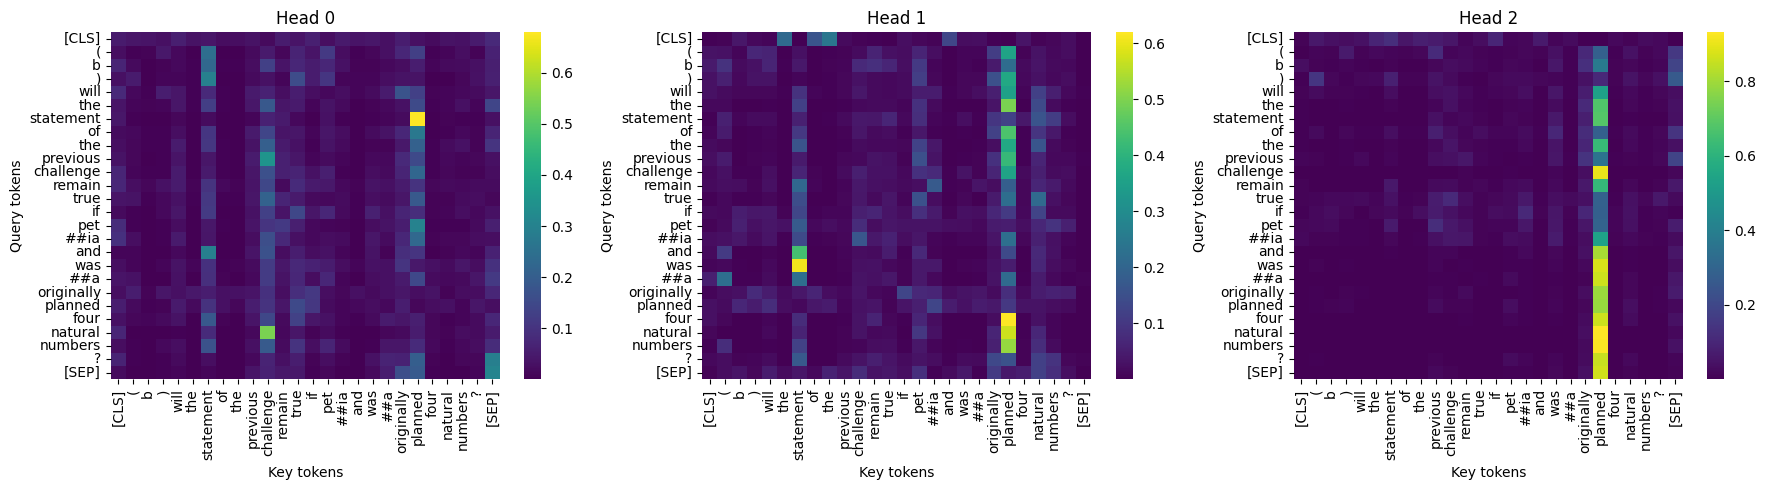



Backbone model: tbs17/MathBert

Text: ( b) Will the statement of the previous challenge remain true if Petia and Wasa originally planned four natural numbers?



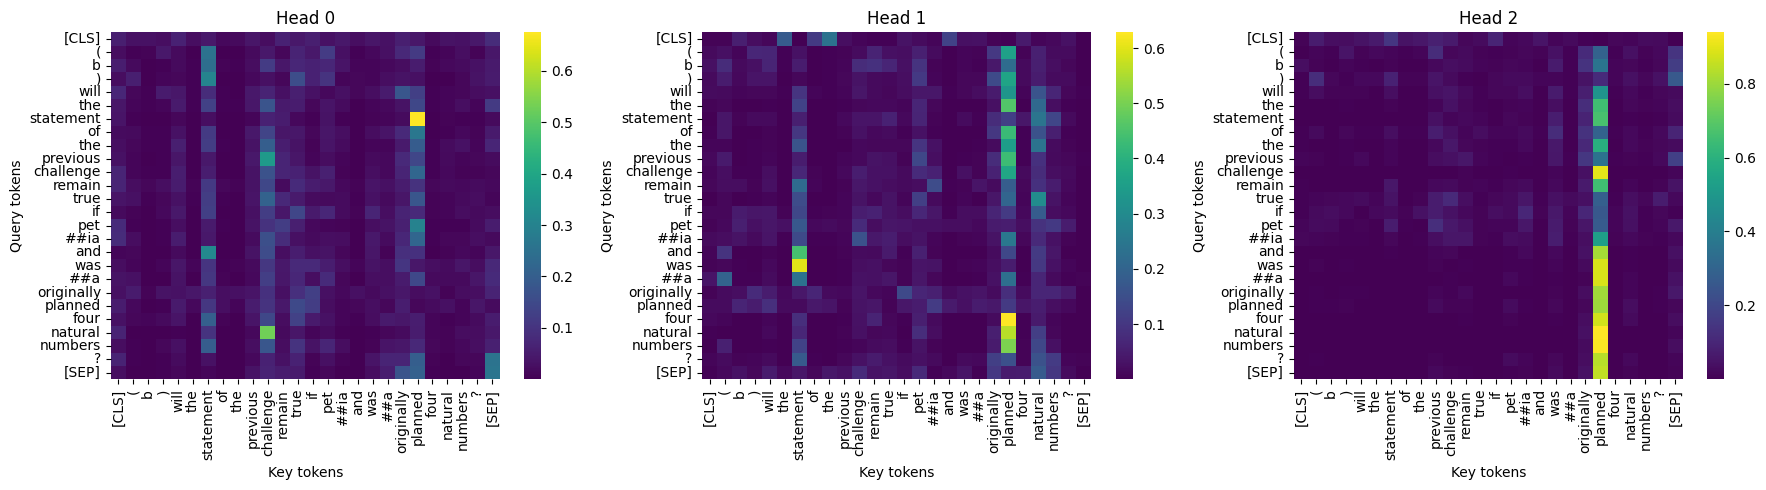



Backbone model: cointegrated/rubert-tiny2

Text: The quadratic three-member graph with the coefficients has two points with the coordinates. Show that if the distance between them is the whole number, then the fraction is parallel to the abscisse axis.



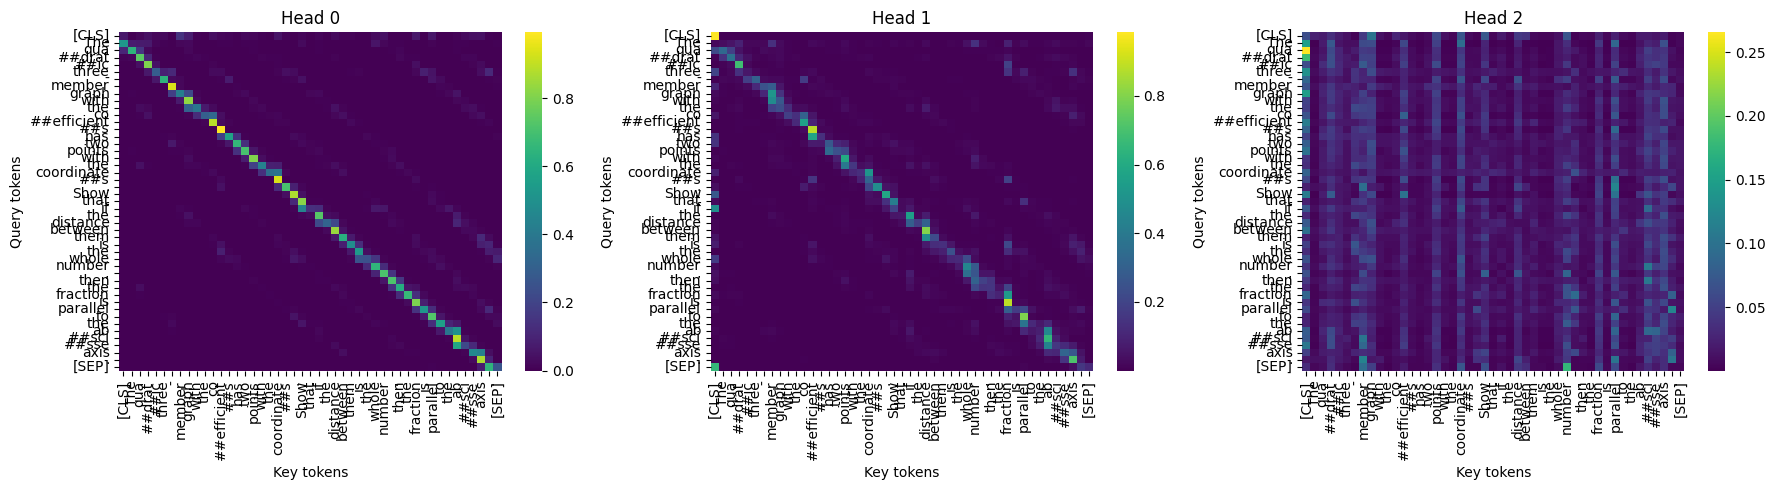



Backbone model: cointegrated/rubert-tiny2

Text: The quadratic three-member graph with the coefficients has two points with the coordinates. Show that if the distance between them is the whole number, then the fraction is parallel to the abscisse axis.



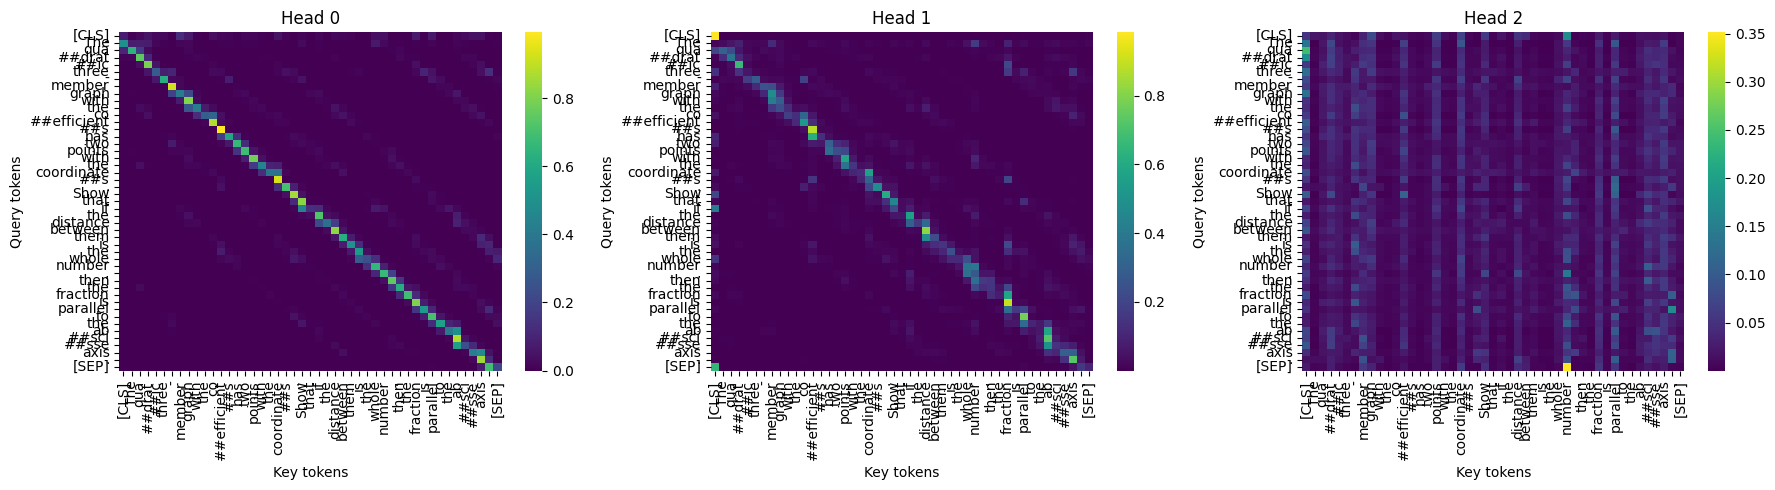



Backbone model: tbs17/MathBert

Text: The quadratic three-member graph with the coefficients has two points with the coordinates. Show that if the distance between them is the whole number, then the fraction is parallel to the abscisse axis.



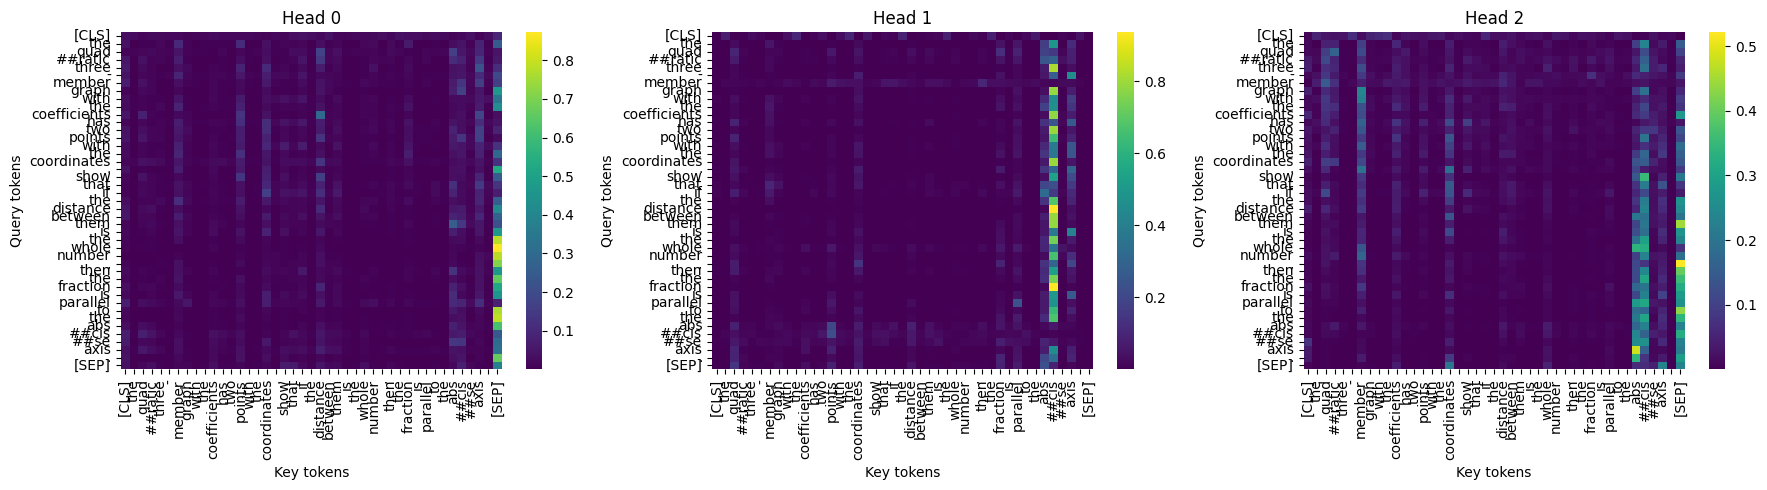



Backbone model: tbs17/MathBert

Text: The quadratic three-member graph with the coefficients has two points with the coordinates. Show that if the distance between them is the whole number, then the fraction is parallel to the abscisse axis.



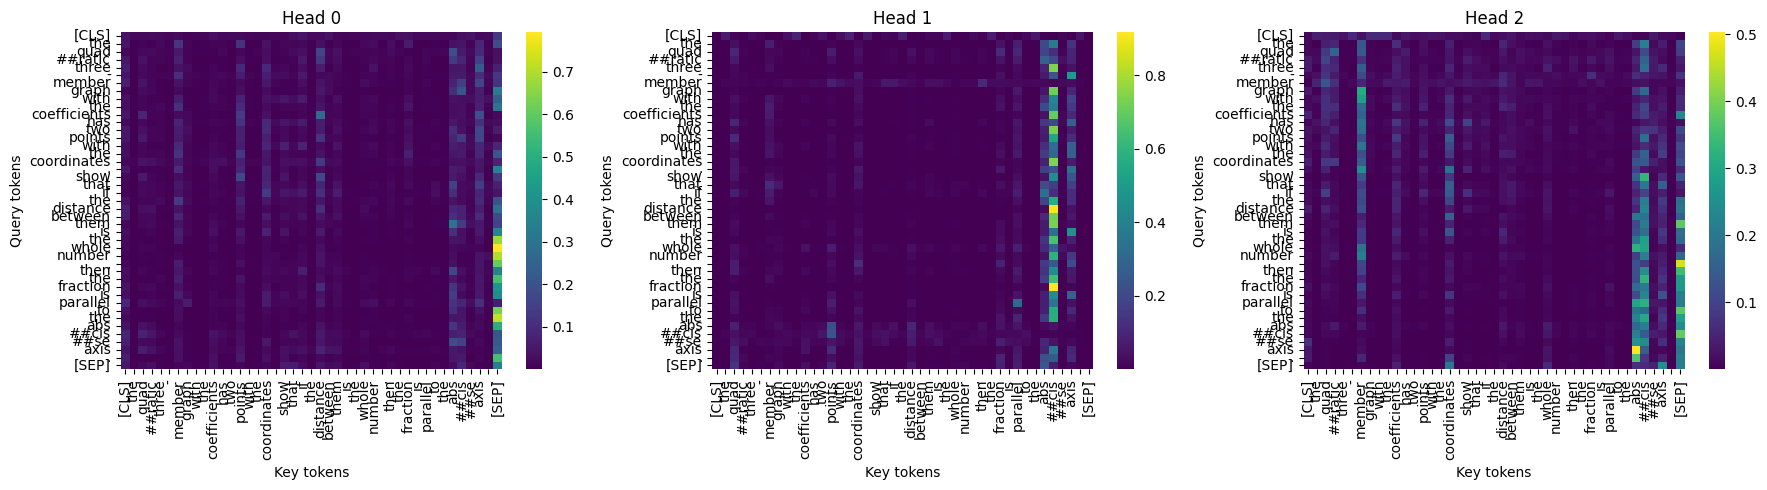

In [23]:
finetuned_models = [
    rubert_frozen,
    rubert_full,
    mathbert_frozen,
    mathbert_full
]

for text in texts:
    for model in finetuned_models:
        print("\n")
        print(f"Backbone model: {model.backbone.config._name_or_path}\n")
        draw_first_layer_attention_maps([0, 1, 2], text, model)

#### Интерпретация

**RuBERT-tiny2:**

После дообучения карты внимания первого слоя практически не изменились. Head 0 и Head 1 сохранили диагональные паттерны, а Head 2 продолжает распределять внимание между отдельными токенами. Заметны лишь небольшие изменения интенсивности внимания.

**MathBERT:**

Карты также остались очень похожими на исходные. Головы по-прежнему концентрируются на отдельных токенах, формируя характерные вертикальные полосы. Изменения распределения внимания незначительны.

**Вывод:**

Несмотря на улучшение качества классификации, структура внимания первого слоя практически не изменилась.

Вероятно, при дообучении модель в большей степени адаптировала более глубокие слои и классификационную голову, сохранив базовые механизмы обработки текста в первом слое.

Это показывает, что улучшение качества классификации не обязательно сопровождается заметными изменениями карт внимания ранних слоёв.